(microbiome-analysis)=
# Exploring a soil microbiome in R

*What can soil microbes tell us about the environments they live in? Conversely, how does the environment "shape" the soil microbiome?* 

In this practical, you will explore a soil microbiome dataset, develop a question and communicate what you find. You can work through the analysis in a small group; share the coding, checking and interpretation, and swap roles as you go.

## Learning goals and preparation

By the end, you should be able to inspect and wrangle a community dataset, use plots to explore patterns, turn an observation into a testable hypothesis, and write a script that reproduces your analysis. You will also need to think about what the data can and cannot tell you. You should have a working knowledge of R; revisit the data wrangling, exploration and visualisation sections of [Data Management and Visualization in R](data-r.ipynb) before you start. The habits you learned there—keeping the original data, recording what you do, and inspecting distributions before drawing conclusions—will be just as useful here.

Useful MQB references as you work include [data wrangling principles](data-r.ipynb#some-data-wrangling-principles), [R data structures](r.ipynb#r-data-structures), [importing data and relative paths](r.ipynb#importing-and-exporting-data), [exploratory plots](data-r.ipynb#data-exploration-with-basic-plotting), [building plots with `ggplot2`](data-r.ipynb#advanced-plotting-ggplot), and [running scripts with `source()`](r.ipynb#using-source). You can return to the relevant section when you need it rather than reading every chapter in full beforehand.

The data handling uses base R, and most plots use the `ggplot2` package. If `ggplot2` is not installed, we will show you how to install it before using it. Read this page in your browser and use RStudio to run the examples. 

In the RStudio console create a new script called `code/microbiome_analysis.R` using the `file.create()` command in the practicals folder you have created. 

Copy the code blocks below into it in order. By the end, you will have a single script that runs the complete analysis using `source()`. Place the cursor on a line and select **Run** (or select several lines and run them together). Keep the same R session open as you work: later commands use data and results created earlier. The outputs on this page are examples. Look at your own results in RStudio's Console and Plots panes as you go.

### Set up your files in RStudio

Let's first organise the files. Following the MQB convention, put scripts in `code/`, the original data and metadata in `data/`, and your figures and other outputs in `results/`. Choose a folder for the practical and arrange it like this:

```text
microbiome-practical/              ← working directory
├── code/
│   └── microbiome_analysis.R      ← your script
├── data/
│   └── microbiome/
│       ├── V.profile_bootstrap_cleaned_Oct18_ver4.csv
│       └── microbiome_metadata.md
└── results/                       ← figures and other outputs
```

```{admonition} Use AI to learn from the code
:class: tip
As you work through this practical, you can ask the free ChatGPT or Gemini chat interface to explain code, not just to write it for you. For example, when you reach the `setwd()` and `getwd()` commands below, paste them into the chat and ask: “Explain what each command does, how the working directory affects file paths, and what I should check before running the next step.” Replace your own folder path with a generic example before sharing it.

**Check:** Compare the explanation with what you see when you run `getwd()` in RStudio. Can you explain to your group where R will look for a file? AI can make mistakes, so use the R chapter and R's help pages to check anything that is unclear.
```

1. Create the practical folder and its `code`, `data/microbiome` and `results` subfolders. Download the CSV and metadata using the links below and put them in `data/microbiome/`. Keep these original inputs unchanged.
2. In the RStudio **Console**, use `setwd()` to set the **practical folder**, not one of its subfolders, as your working directory. Replace the example path with the actual path to your folder:

   ```r
   setwd("/path/to/microbiome-practical")
   getwd()
   ```

   On Windows you can use forward slashes, for example `setwd("C:/Users/your-name/microbiome-practical")`. Check that `getwd()` displays your practical folder. Run `setwd()` again in the Console when you start a new R session if needed. For more on this, see [the R workspace and working directory](r.ipynb#the-r-workspace-and-working-directory).
3. Create your R script in RStudio and save it as `code/microbiome_analysis.R`. Copy and run the examples in order, keeping the same R session open.
4. The import command below reads from `data/microbiome/` relative to the working directory; save your figures and other outputs in `results/`. If you choose a different location for the CSV, adjust the import path. Keep your computer-specific `setwd()` command in the Console rather than the shared script so that others can run the script from their own practical folder.

Alternatively, run `soil <- read.csv(file.choose())` in RStudio and select the CSV in `data/microbiome/`. Record where the file came from so the analysis remains reproducible.

## The question and the data

At the [Nash's Field experiment at Silwood Park](https://www.imperial.ac.uk/silwood-park/our-outdoor-laboratory/field-experiments/nashs-field-experiment/), grassland soils have received different treatments, including lime and pesticides. Could bacterial communities in acidic soils respond differently to pesticides from those in more neutral soils? We will explore the data for patterns that might help us develop questions like this for further study. Lime was added to some plots to change the soil pH. Note that the dataset records whether a plot was limed, not its measured pH.

Download the [data CSV](../data/microbiome/V.profile_bootstrap_cleaned_Oct18_ver4.csv) and its {download}`metadata <../data/microbiome/microbiome_metadata.md>`. Rows represent soil samples; the first six columns contain sample information and the remaining columns contain sequence counts for operational taxonomic units (OTUs).

The sample information also includes `ATP.biomass`, a measurement of adenosine triphosphate (ATP) in the soil. ATP is a molecule used by living cells to transfer energy; the measurement provides an indicator related to microbial activity. The values are in nanomoles per gram of soil (nmol/g); further measurement details are not available, and three samples have missing values. We will keep it in the sample data and return to it as a possible direction for further analysis at the end of the chapter.

Before you start, read the metadata to find out what each column contains. Soil cores were divided into five consecutive 10 cm sections: depth categories 1–5 correspond to 0–10, 10–20, 20–30, 30–40 and 40–50 cm, respectively. Sequences were grouped into OTUs at 97% similarity. An OTU is not necessarily a species, and the sequence counts are observations from sequencing rather than direct counts of organisms in the soil.

```{admonition} What we do not yet know
:class: caution
Some details are missing from this dataset: plot and core identifiers, which rows at different depths came from the same core or plot, treatment allocation and replication, and the exact steps used to subsample and filter sequences. The row number is not a confirmed plot identifier. Until you know more, you cannot assume that rows are independent experimental replicates or use the plots to *statistically* establish causal treatment effects. Keep this in mind as you proceed with the analyses below. 
```

## 1. Import and inspect

First, read the CSV from `data/microbiome/` and add the commands to your script in `code/`. Let's see how large the table is, what kinds of variables it contains, and what the first few rows look like. The first column has a blank header in the CSV, so `read.csv()` names it `X` by default. Keep the original data file unchanged as you work.

In [1]:
# Read the CSV from the data folder into an R object called soil
soil <- read.csv("data/microbiome/V.profile_bootstrap_cleaned_Oct18_ver4.csv")
# Inspect its dimensions, column names, types and first few rows
dim(soil)
names(soil)[1:12]
str(soil[, 1:6])
head(soil[, 1:6])

[1]   58 9688

[1] "X"           "Cide"        "Liming"      "Depth"       "Moisture"   
 [6] "ATP.biomass" "OTU100"      "OTU10000"    "OTU1001"     "OTU10010"   
[11] "OTU10021"    "OTU10027"

'data.frame':	58 obs. of  6 variables:
 $ X          : int  1 2 3 4 5 6 7 8 9 10 ...
 $ Cide       : chr  "Control" "Control" "Control" "Control" ...
 $ Liming     : chr  "limed" "limed" "limed" "limed" ...
 $ Depth      : int  1 2 3 4 5 1 2 3 4 5 ...
 $ Moisture   : int  26 25 25 25 19 33 33 19 20 15 ...
 $ ATP.biomass: num  NA 4.51 20.72 43.81 5.73 ...


,X,Cide,Liming,Depth,Moisture,ATP.biomass
,<int>,<chr>,<chr>,<int>,<int>,<dbl>
1,1,Control,limed,1,26,NA
2,2,Control,limed,2,25,4.514441
3,3,Control,limed,3,25,20.724364
4,4,Control,limed,4,25,43.805707
5,5,Control,limed,5,19,5.725536
6,6,Control,unlimed,1,33,132.117217


**What does this code do?**

The first line asks R to read a comma-separated values (CSV) file. The text in quotes is the file's path, relative to your practical working directory. `read.csv()` reads its rows and columns into a data frame, and `<-` gives that data frame the name `soil` so we can use it in later commands. You will often hear a named piece of data in R called an *object*: it can be a single value, a vector or a table such as this data frame. R holds `soil` in your current session; the CSV file itself stays unchanged. See [R Data Structures](r.ipynb#r-data-structures) for examples of the different kinds of data R can store. See [Importing and Exporting Data](r.ipynb#importing-and-exporting-data) and [Relative paths](r.ipynb#relative-paths) in the R chapter for more detail.

Now let's inspect what we read. `dim(soil)` gives the numbers of rows and columns; `names(soil)[1:12]` shows the first 12 column names. In `soil[, 1:6]`, the comma separates rows from columns: the blank before it selects all rows, while `1:6` selects the first six columns. `str()` shows the structure and variable types, and `head()` shows the first few rows. If the indexing feels unfamiliar, revisit [Data frames](r.ipynb#data-frames) and [Indices and Indexing](r.ipynb#accessing-parts-of-data-stuctures-indices-and-indexing).

If R cannot find the file, check `getwd()` and confirm that the CSV is in `data/microbiome/` under that folder, with the filename shown in the code.

**Discuss:** What does one row represent? Which columns describe samples and which describe OTUs? Compare the answers with the metadata. How many missing values are there in each sample variable?

In [2]:
colSums(is.na(soil[, 1:6]))
table(soil$Cide, soil$Liming)
table(soil$Depth, soil$Liming)

X        Cide      Liming       Depth    Moisture ATP.biomass 
          0           0           0           0           0           3

         
          limed unlimed
  Control    10       9
  Insect      9      10
  Mollusc    10      10

   
    limed unlimed
  1     6       6
  2     6       5
  3     6       6
  4     6       6
  5     5       6

**What does this code do?**

`is.na()` identifies missing entries, and `colSums()` counts them in each selected column: R counts `TRUE` as 1 and `FALSE` as 0. The `$` selects a named column. Each `table()` counts the rows in each combination of its two variables.

These tables count **samples**, which are not necessarily independent plots. Are the sample counts equal across groups? Think about how unequal counts or missing values might affect a plot.

```{admonition} Ask an AI assistant: inspecting data
:class: tip
In the free ChatGPT or Gemini chat interface, paste your dimensions, column names and a small summary (not the entire CSV), then ask: “Explain R code for checking column types and missing values in this dataset. What should I inspect before plotting?”

**Check:** Run the suggestions, compare the output with the metadata, and explain to your group what each command does. A chatbot cannot see your R session unless you provide context.
```

## 2. Wrangle the sample and OTU data

The table we just read contains two kinds of information: the first six columns describe the samples, while the remaining columns contain the OTU sequence counts. It will be easier to work with these if we make two smaller tables in R: `sample_info` for the sample details and `otu` for the counts. We can then calculate diversity from the counts and relate it to the sample details. The original `soil` table will still be available.

Let's also check the column types, missing values and negative counts. There are a lot of OTU columns, so we will look at just a small part of the counts table rather than printing all of it!

In [3]:
sample_info <- soil[, 1:6]
# Labels for the five soil depth intervals, in centimetres
depth_labels <- c("0–10", "10–20", "20–30", "30–40", "40–50")
otu <- soil[, -(1:6)]
stopifnot(nrow(sample_info) == nrow(otu), all(vapply(otu, is.numeric, logical(1))))
c(samples = nrow(otu), otus = ncol(otu), missing_counts = sum(is.na(otu)), negative_counts = sum(otu < 0, na.rm = TRUE))
# Stop before calculating diversity if any OTU count is missing or negative
if (anyNA(otu) || any(otu < 0, na.rm = TRUE)) {
  stop("The OTU table contains missing or negative counts; check the data before continuing.")
}
head(otu[, 1:6])

samples            otus  missing_counts negative_counts 
             58            9682               0               0

,OTU100,OTU10000,OTU1001,OTU10010,OTU10021,OTU10027
,<int>,<int>,<int>,<int>,<int>,<int>
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,0,1,0,4,0
4,0,0,0,0,0,0
5,0,0,0,0,0,0
6,0,0,0,0,0,0


**What does this code do?**

The first line selects the six sample-information columns; the minus sign in `-(1:6)` selects all columns except those six. `stopifnot()` stops with an error if a check is false: here it checks that both objects have the same number of rows and every OTU column is numeric. `vapply()` applies `is.numeric()` to each column, and `all()` checks that every answer is `TRUE`. The named values inside `c()` report dimensions and counts of missing and negative entries. The next check stops the script if any OTU count is missing or negative. If that happens, go back to the data and metadata, check how the file was read, and ask a tutor for help before continuing; don't replace missing counts with zero without knowing what they mean. `head()` shows a small part of the OTU table.

### Explore the environmental variables first

Before looking for patterns in the microbiome, ask how the environmental variables relate to one another. This is a fundamental part of data exploration: if two possible explanatory variables change together, a pattern in richness or diversity may be difficult to associate with either one separately. For example, suppose deeper samples also tend to be wetter. If diversity differs with depth, could moisture be involved too? With strongly correlated predictors, later statistical models can have difficulty separating their associations with the response, making individual estimates and their interpretation uncertain.

Let's start with soil moisture and depth. Each depth value represents a 10 cm interval, from 0–10 cm (category 1) to 40–50 cm (category 5). Let's make a simple boxplot of moisture for each interval using base R. Moisture is recorded as a percentage; the metadata do not specify the measurement method.

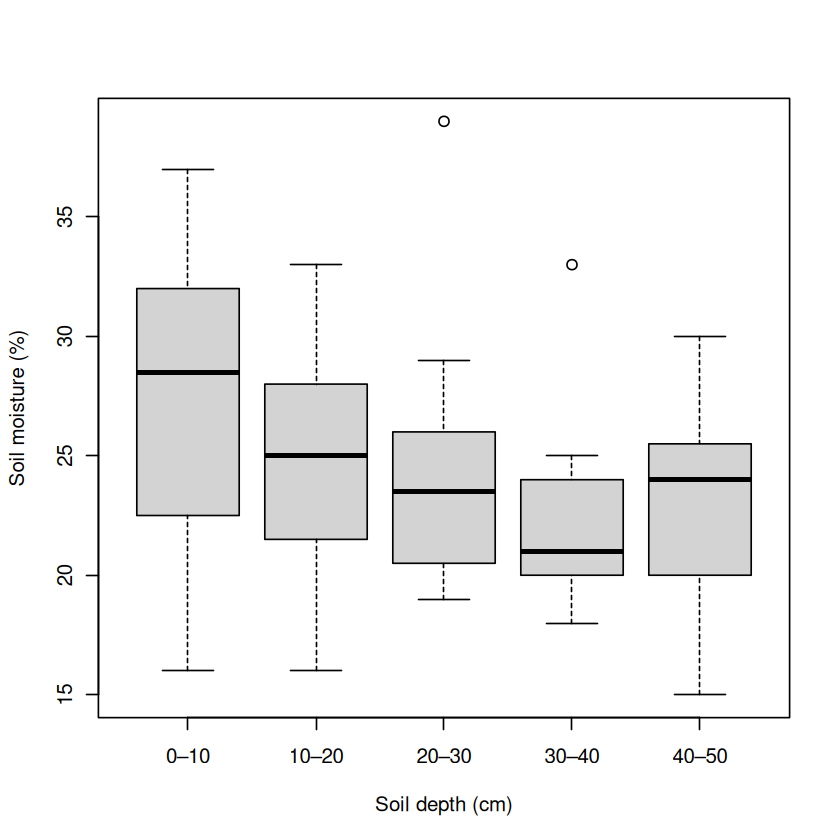

In [4]:
# A first look at moisture across the depth categories using base R
plot(factor(sample_info$Depth, levels = 1:5, labels = depth_labels), sample_info$Moisture,
     xlab = "Soil depth (cm)", ylab = "Soil moisture (%)")

**What does this code do?** `factor(sample_info$Depth)` tells R to treat depth as categories. When the x variable is a factor, base R's `plot()` makes a boxplot of moisture for each category. `xlab` and `ylab` give the axes meaningful labels. The labels show the five sampled intervals, in centimetres.

### Make the same plot with `ggplot2`

Now let's make the same comparison with `ggplot2`, a package for building plots in layers. If it is not already installed, run `install.packages("ggplot2")` **once in the RStudio Console**. Then add `library(ggplot2)` to your analysis script and run it in each new R session. You don't need to put the installation command in the script.

The code below creates a plot from `sample_info`, maps depth to the x-axis and moisture to the y-axis, and adds a boxplot layer. `print()` displays the plot both in RStudio and when the whole script is run with `source()`. Compare it with the base R plot: both show moisture across the same depth categories, though their default appearance differs. See [Beautiful graphics in R](data-r.ipynb#beautiful-graphics-in-r) and [Advanced plotting: `ggplot`](data-r.ipynb#advanced-plotting-ggplot) for an introduction to layers and aesthetic mappings.

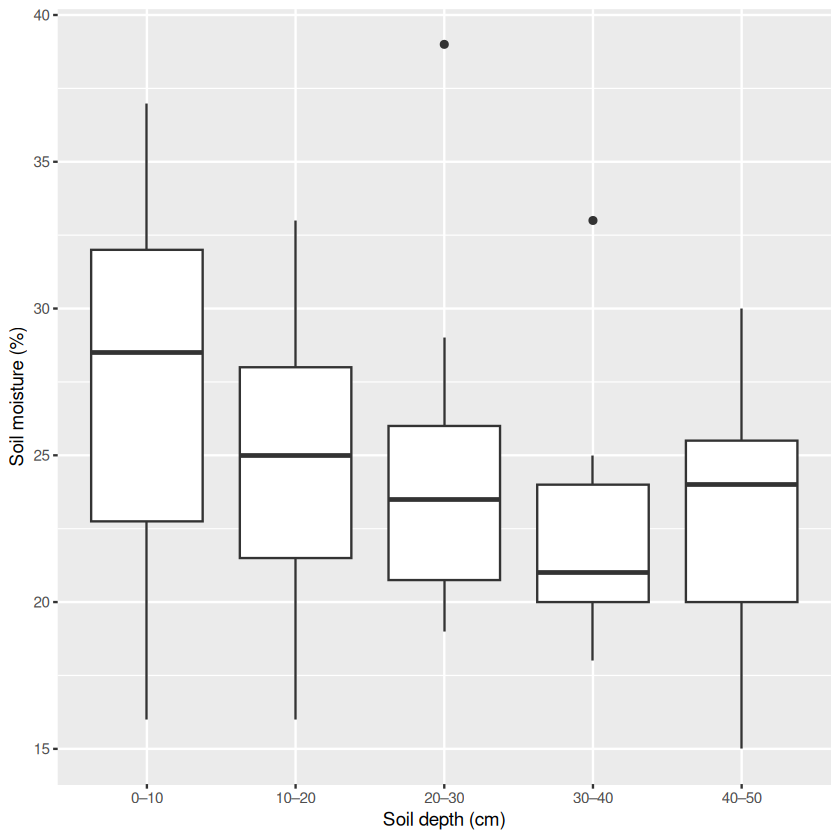

In [5]:
library(ggplot2)

moisture_depth_plot <- ggplot(sample_info, aes(x = factor(Depth, levels = 1:5, labels = depth_labels), y = Moisture)) +
  geom_boxplot() +
  labs(x = "Soil depth (cm)", y = "Soil moisture (%)")
print(moisture_depth_plot)

`ggplot(sample_info, aes(...))` supplies the data and maps variables to axes. `geom_boxplot()` chooses how to display them, and `labs()` labels the axes. The `+` signs add these layers to the plot. `factor(Depth, levels = 1:5, labels = depth_labels)` tells ggplot to show the five depth intervals in order. We defined `depth_labels` when we created `sample_info`. Saving the plot as `moisture_depth_plot` lets us display or reuse it later.

Now make another plot to compare moisture across liming categories. This time, we will add the individual observations too.

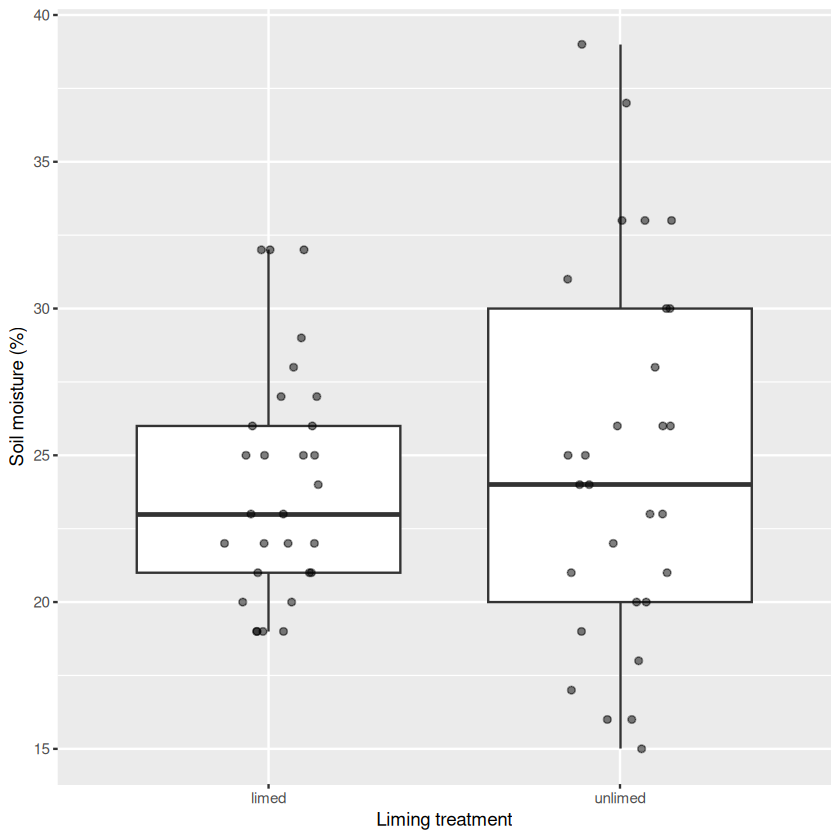

In [6]:
moisture_liming_plot <- ggplot(sample_info, aes(x = Liming, y = Moisture)) +
  geom_boxplot() +
  geom_jitter(position = position_jitter(width = 0.15, height = 0, seed = 42),
              alpha = 0.5) +
  labs(x = "Liming treatment", y = "Soil moisture (%)")
print(moisture_liming_plot)

`geom_jitter()` adds a point for each sample. The small sideways shifts make overlapping points easier to see; they do not change the data. The seed keeps the point positions reproducible. `alpha` controls point transparency.

**Discuss:** Does moisture appear to change across depth categories? How much do the samples vary within each category? Is moisture distributed similarly in limed and unlimed samples? Try making a plot that shows both depth and liming, and check how many samples occur in each group. If moisture and depth vary together, how might this complicate an interpretation of diversity differences across depths? Are there enough samples covering different combinations to help separate their associations?

Now imagine that measured soil pH and moisture were strongly correlated. If community diversity also changed with pH, it could be difficult to tell whether pH, moisture, both, or another associated factor was related to the pattern. A correlation by itself does not establish which variable causes the change. **This dataset does not contain measured pH**, so you cannot calculate a moisture–pH correlation here; liming is a treatment category, not a substitute for the missing pH measurements. Also remember that the sampling and plot structure is unknown: these visual comparisons are exploratory.

If you later obtain two measured numerical environmental variables, a labelled scatter plot is a useful way to inspect their relationship, including its shape and any unusual points, before calculating a correlation coefficient. See [Correlations](regress.ipynb#correlations) for interpreting correlations, [Exploring the data](mul-expl.ipynb#exploring-the-data) and the multiple explanatory variables chapter for correlated predictors, and [Experimental design and data exploration](exp-design.ipynb#data-exploration) for the role of study design.

```{admonition} Ask an AI assistant: interpreting environmental patterns
:class: tip
Describe the variables, their types and what you see in your plots. Ask ChatGPT or Gemini: “If moisture varies with depth, why might it be difficult to interpret a relationship between depth and microbial diversity? Suggest two alternative explanations and a useful next plot.”

**Check:** Compare the answer with your plots and the metadata. Does it distinguish association from causation and recognise that depth is recorded as categories? The assistant cannot infer measured pH or the missing plot design from these data.
```

Each row of `sample_info` should still correspond to the same row of `otu`. This matters: if the rows get out of order, we could assign an OTU count to the wrong sample! Check the alignment whenever you filter or reorder the data. Now, find the OTUs with no recorded sequences in any sample. We will keep the full counts table, `otu`, and make a new table, `otu_observed`, containing only OTUs recorded in at least one sample.

In [7]:
zero_otus <- colSums(otu, na.rm = TRUE) == 0
sum(zero_otus)
otu_observed <- otu[, !zero_otus, drop = FALSE]
c(remaining_otus = ncol(otu_observed), samples = nrow(otu_observed))

[1] 452

remaining_otus        samples 
          9230             58

**What does this code do?**

`colSums(otu)` adds each OTU's counts across samples. Comparing the totals with `== 0` produces a `TRUE`/`FALSE` value for each column; `sum(zero_otus)` counts the `TRUE` values. The `!` means “not”, so we keep columns that are not all zero. `drop = FALSE` keeps the result as a table even if only one column is selected. The original `otu` object remains available.

```{admonition} Ask an AI assistant: wrangling
:class: tip
Paste the dimensions and the first few column names, then ask: “Explain how to separate the first six metadata columns from the remaining OTU columns in R. How can I check that rows still match?”

**Check:** Compare the proposed dimensions and row order with the original. Explain the indexing to your group before using the code. Keep the original data unchanged.
```

### Explore sequencing totals and richness

The reported processing included randomly subsampling sequences, but the exact target and filtering steps for this file still need confirmation. What do the totals actually look like? We can also calculate *observed richness*: the number of OTUs with a nonzero count in each sample. This depends partly on sequencing, so it doesn't tell us about every organism present.

   sequences       richness     
 Min.   :4870   Min.   : 226.0  
 1st Qu.:4936   1st Qu.: 841.8  
 Median :4964   Median :1057.5  
 Mean   :4956   Mean   :1018.8  
 3rd Qu.:4978   3rd Qu.:1284.0  
 Max.   :5000   Max.   :1568.0  

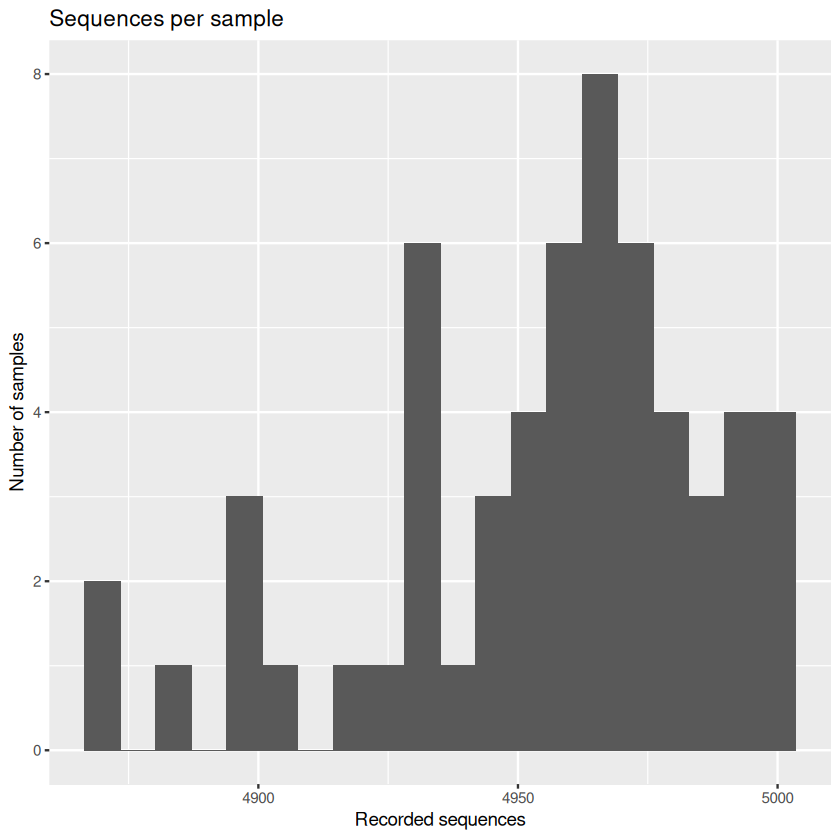

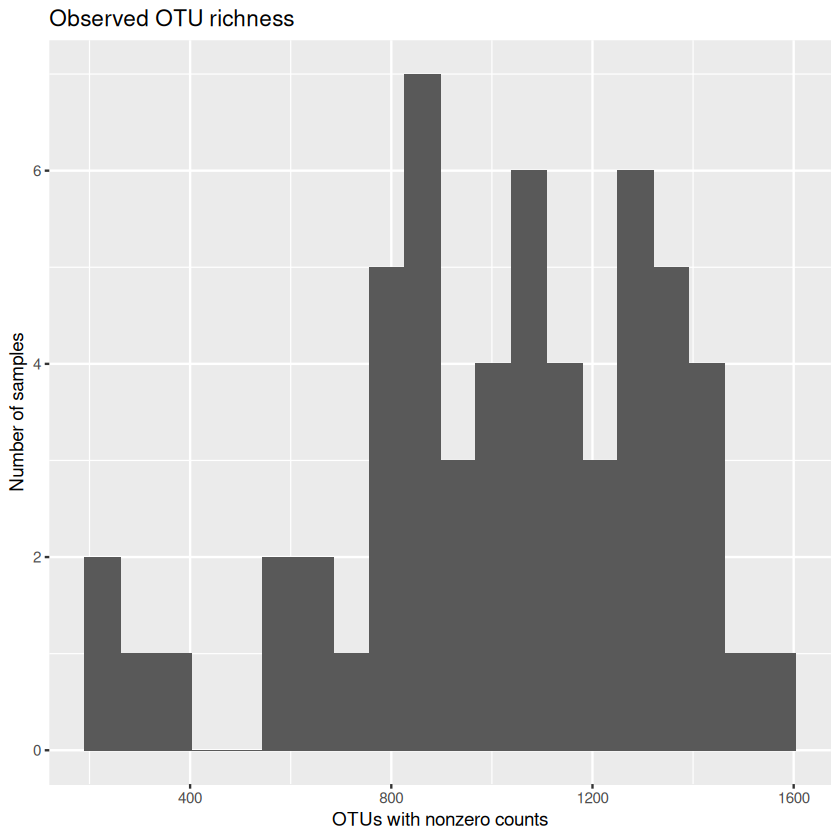

In [8]:
sample_info$sequences <- rowSums(otu_observed)
sample_info$richness <- rowSums(otu_observed > 0)
summary(sample_info[, c("sequences", "richness")])

sequences_plot <- ggplot(sample_info, aes(x = sequences)) +
  geom_histogram(bins = 20) +
  labs(title = "Sequences per sample", x = "Recorded sequences", y = "Number of samples")
print(sequences_plot)
richness_histogram <- ggplot(sample_info, aes(x = richness)) +
  geom_histogram(bins = 20) +
  labs(title = "Observed OTU richness", x = "OTUs with nonzero counts", y = "Number of samples")
print(richness_histogram)

**What does this code do?**

`rowSums()` adds values across each sample's OTUs. For richness, `otu_observed > 0` first makes a table of `TRUE` and `FALSE` values; summing each row counts OTUs with at least one recorded sequence. We save both results as new columns of `sample_info`. `summary()` gives a numerical overview. Each `ggplot()` maps a variable to the x-axis, and `geom_histogram(bins = 20)` groups its values into 20 intervals; the height shows the number of samples in each interval. Change the number of bins and see how it affects the picture.

**Discuss:** What do the distributions look like? Are sample sequencing totals equal? How might sequencing depth affect observed richness? Two types of curve can help us think about sampling. A *sample accumulation curve* shows how the number of OTUs found increases as more soil samples are added. A *sequence rarefaction curve* shows how the number of OTUs found within a sample changes as more of its sequences are examined. In rarefaction, sequences are randomly selected from a sample to compare what would be found at different sequencing depths. A curve that starts to level off suggests that further sampling may find fewer additional OTUs, but it does not prove that all OTUs have been found. We have not calculated either curve here.

```{admonition} Sequencing and sampling caveat
:class: caution
The counts have already been processed, including random subsampling. Very rare OTUs with one or two reads may have been removed afterwards because some could represent sequencing errors. This may help explain why the totals in the file range from 4,870 to 5,000 sequences, although the precise subsampling target and filtering steps need confirmation. As the rarefaction discussion suggests, how many OTUs we find depends partly on how many sequences we examine. Subsampling and filtering can leave some OTUs undetected, so differences in observed richness may reflect sampling and sequencing as well as biology. A zero means that no sequences for that OTU were recorded in the sample; it does not prove that the organism was absent.
```

### From richness to diversity

Richness counts how many OTUs were observed, but it does not tell us how the sequences are distributed among them. Imagine two samples, each with two OTUs. In one sample the sequence counts are 50 and 50; in the other they are 99 and 1. Both have the same richness, but the first community is more *even*: the two OTUs have similar relative abundances. A diversity measure can capture this difference as well as richness, so it can reveal changes that a count of OTUs alone would miss. Neither measure tells us which OTUs are present.

One commonly used measure is **Simpson diversity**, $1 - \sum_i p_i^2$, where $p_i$ is the proportion of a sample's sequences assigned to OTU $i$. It is the probability that two sequences drawn independently at random, with replacement, belong to different OTUs. Values near zero indicate that the recorded sequences are dominated by one OTU; higher values indicate greater diversity. The measure is especially sensitive to common OTUs. We will calculate it using base R from the relative sequence counts for each sample. These proportions describe the sequences observed, not necessarily the true proportions of organisms in the soil.

In [9]:
# Check that every sample has a positive sequence total before division
stopifnot(all(sample_info$sequences > 0))
# Divide each row of counts by that sample's total
relative_abundance <- sweep(as.matrix(otu_observed), 1, sample_info$sequences, "/")
# Calculate 1 minus the sum of squared proportions for each sample
sample_info$simpson <- 1 - rowSums(relative_abundance^2)
summary(sample_info[, c("richness", "simpson")])

    richness         simpson      
 Min.   : 226.0   Min.   :0.9689  
 1st Qu.: 841.8   1st Qu.:0.9887  
 Median :1057.5   Median :0.9934  
 Mean   :1018.8   Mean   :0.9910  
 3rd Qu.:1284.0   3rd Qu.:0.9954  
 Max.   :1568.0   Max.   :0.9976  

**What does this code do?**

Let's unpack this calculation:

- `stopifnot(all(sample_info$sequences > 0))` checks that every sample has at least one recorded sequence. We need a positive total before dividing by it.
- `as.matrix(otu_observed)` turns the OTU table into a numeric matrix. `sweep(..., 1, sample_info$sequences, "/")` divides each **row** (`1`) by the matching sample's sequence total. Each result is that OTU's proportion of the sample's sequences: for example, 50 out of 100 gives 0.5.
- `relative_abundance^2` squares each proportion. `rowSums()` adds the squared proportions within each sample; subtracting the total from 1 gives Simpson diversity. The result is saved as `sample_info$simpson`.
- `summary()` shows the distributions of richness and Simpson diversity across samples. Each value describes one sample, not a treatment as a whole.

**Discuss:** In the two-OTU example above, which sample would have the higher Simpson diversity? Try calculating it by hand. What information does it add to richness, and what does it still leave out?

In this dataset the Simpson values are all close to 1 (roughly 0.969 to 0.998). A plot that shows only this narrow range can make small numerical differences look large, so read the axis labels and report the values as well as describing the plot. Think about the variation within each group before making comparisons.

*Optional:* Another way to make Simpson diversity easier to picture is to ask how many equally common OTUs would give the same value. You can calculate this as `1 / (1 - simpson)`. This is an equivalent number of equally common OTUs, not a count of the OTUs actually observed.

### What do the abundance distributions look like?

Before comparing diversity across treatments, let's look at the sequence abundances that go into it. We will compare the control samples from the shallowest interval (depth category 1, 0–10 cm) in limed and unlimed soil. This holds pesticide treatment and recorded depth category constant while showing a contrast in liming. There are two samples in each category; we will plot all four, so we can see variation between samples as well as between categories.

The following *rank-abundance plots* sort each sample's observed OTUs from most to least abundant, then plot each OTU's proportion of the sample's sequences. The y-axis is logarithmic so that both common and rare OTUs can be seen. Rank 1 means the most abundant OTU **within that sample**: an OTU at the same rank in two samples need not be the same OTU. Zero counts are excluded because they cannot be shown on a log scale. These four samples are illustrative, not proof of a treatment effect.

    X    Cide  Liming Depth richness   simpson
1   1 Control   limed     1     1410 0.9964537
6   6 Control unlimed     1     1124 0.9915746
11 11 Control   limed     1     1497 0.9970755
16 16 Control unlimed     1      921 0.9833659


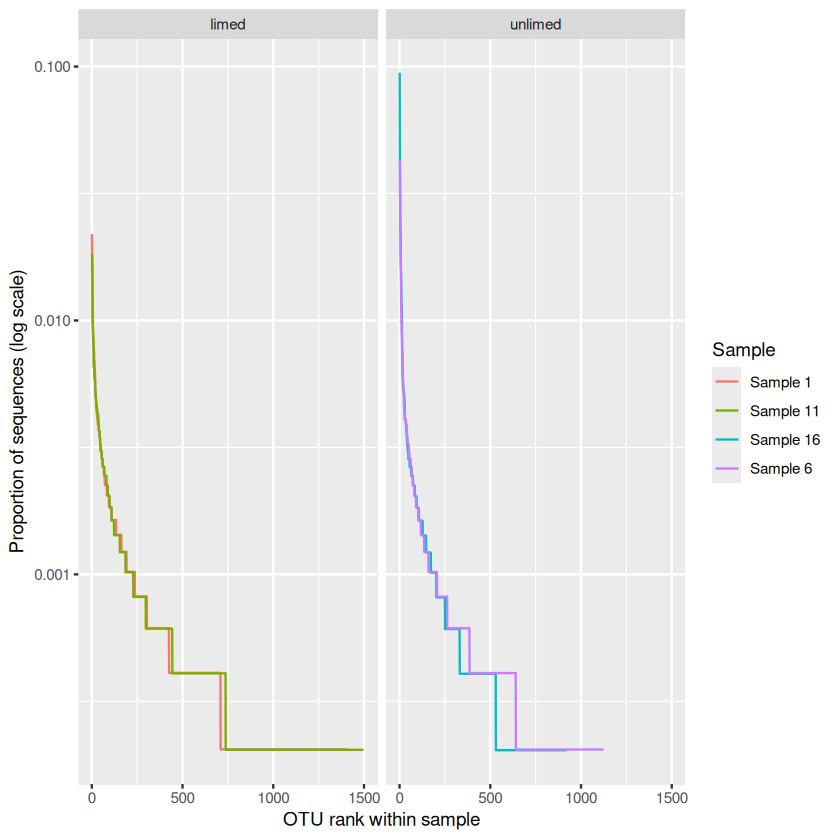

In [10]:
# Select controls at depth 1 and inspect the selected samples
example_rows <- which(sample_info$Cide == "Control" & sample_info$Depth == 1)
print(sample_info[example_rows, c("X", "Cide", "Liming", "Depth", "richness", "simpson")])

# Make a table of ranked positive abundances for the selected samples
rank_tables <- lapply(example_rows, function(i) {
  abundance <- relative_abundance[i, ]
  abundance <- sort(abundance[abundance > 0], decreasing = TRUE)
  data.frame(rank = seq_along(abundance), proportion = abundance,
             Sample = paste("Sample", sample_info$X[i]),
             Liming = sample_info$Liming[i])
})
rank_data <- do.call(rbind, rank_tables)

rank_plot <- ggplot(rank_data, aes(x = rank, y = proportion, colour = Sample)) +
  geom_line() +
  facet_wrap(~ Liming) +
  scale_y_log10() +
  labs(x = "OTU rank within sample", y = "Proportion of sequences (log scale)")
print(rank_plot)

**What does this code do?**

`which()` finds the rows that are both controls and at depth category 1; `&` means both conditions must be true. We print their sample details so we can check the selection. `lapply()` then repeats the same steps for each selected row: take its relative abundances, keep those above zero, sort them from largest to smallest and use `seq_along()` to assign ranks. It returns a list of small tables; `do.call(rbind, rank_tables)` joins their rows into one table, `rank_data`.

In the plot, `aes()` maps rank and proportion to the axes and assigns a colour to each sample. `geom_line()` draws the curves, `facet_wrap(~ Liming)` puts the liming categories in separate panels, and `scale_y_log10()` uses a logarithmic y-axis. Because each sample has its own colour, ggplot draws and labels a separate line for it. See the R chapter's [apply family of functions](r.ipynb#the-apply-family-of-functions) for more on repeating a calculation.

**Discuss:** Which samples have more observed OTUs (longer curves)? Are the common OTUs similarly abundant, or do a few dominate? Compare the two samples within each liming category before comparing categories. How do these patterns relate to their Simpson diversity values? You could repeat this for another depth or pesticide treatment, keeping track of how you selected the samples.

```{admonition} What can an abundance distribution tell us?
:class: tip
To read a curve, start at the left: the first point is the most abundant observed OTU in that sample, followed by the next most abundant, and so on. The height shows each OTU's share of the sample's sequences. A curve that reaches farther to the right contains more observed OTUs. A steep drop suggests that a few OTUs account for much of the sample, while a flatter curve suggests that their observed abundances are more evenly spread.

The vertical axis is logarithmic: equal steps represent equal *ratios*, not equal differences in sequence proportions. Rank is assigned separately within each sample, so lines at the same rank do not necessarily refer to the same OTU. Compare the curves within each treatment as well as across treatments: the plots show four individual samples, not a complete picture of every community in a treatment.

Such patterns can prompt questions about how a community functions and how it responds to change. But a single curve cannot tell us whether the community is stable: to investigate stability, we would need observations through time or measurements of its response to disturbance. Nor does a steep or flat curve, on its own, tell us whether a community is healthy. Remember that these curves describe sequence proportions, which may not exactly match the organisms' abundances in the soil.
```

```{admonition} Interpreting the examples
:class: caution
These are four individual samples, not averages or confirmed independent experimental replicates. Sequencing and subsampling also affect which OTUs are observed. Use the curves to generate questions, and examine the other samples before describing a broader pattern.
```

## 3. Explore patterns visually

Now let's look for patterns. Start with a simple plot, then try grouping the samples differently or using another type of plot. Showing the individual points helps us see variation that means alone can hide. The five depth intervals run from 0–10 cm to 40–50 cm. The code below keeps them in that order for plotting.

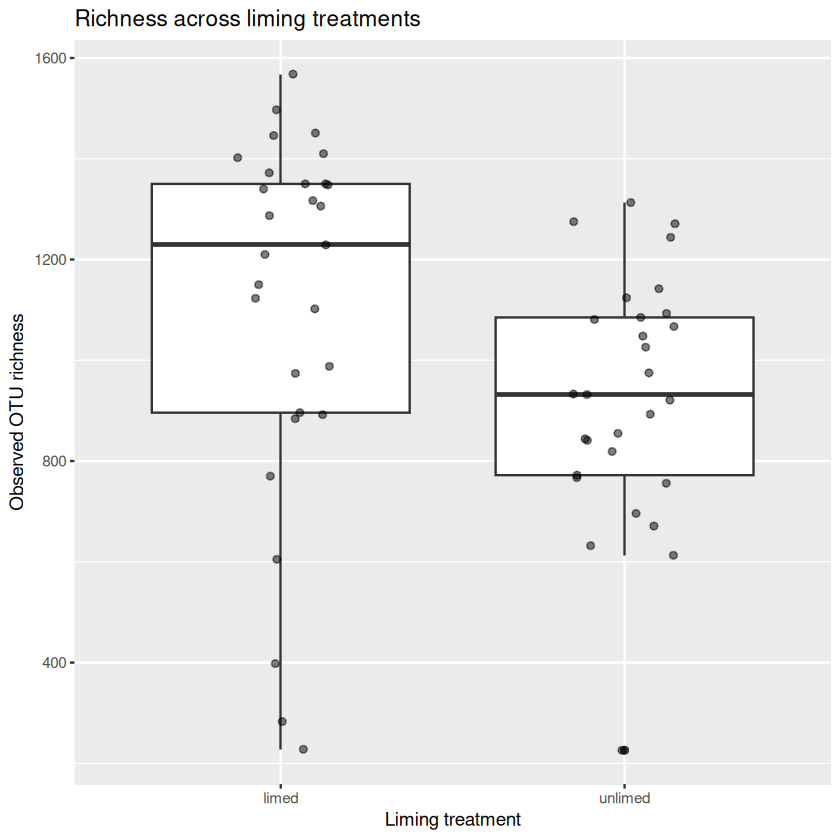

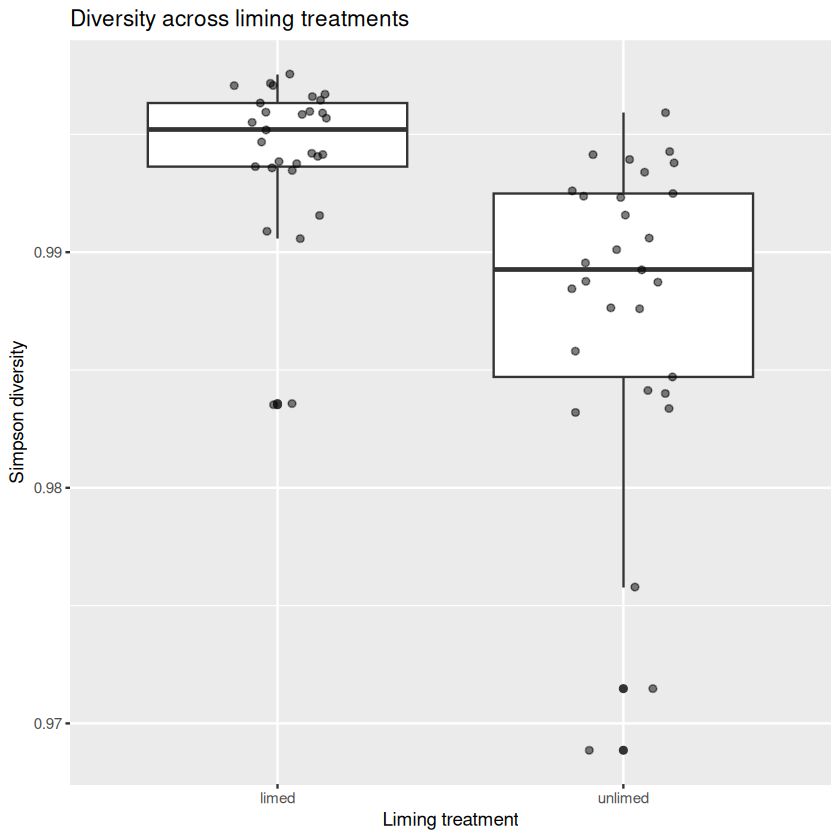

In [11]:
sample_info$Depth <- factor(sample_info$Depth, levels = 1:5, labels = depth_labels, ordered = TRUE)

richness_plot <- ggplot(sample_info, aes(x = Liming, y = richness)) +
  geom_boxplot() +
  geom_jitter(position = position_jitter(width = 0.15, height = 0, seed = 42),
              alpha = 0.5) +
  labs(x = "Liming treatment", y = "Observed OTU richness",
       title = "Richness across liming treatments")
print(richness_plot)

diversity_plot <- ggplot(sample_info, aes(x = Liming, y = simpson)) +
  geom_boxplot() +
  geom_jitter(position = position_jitter(width = 0.15, height = 0, seed = 42),
              alpha = 0.5) +
  labs(x = "Liming treatment", y = "Simpson diversity",
       title = "Diversity across liming treatments")
print(diversity_plot)

**What does this code do?**

`factor(..., ordered = TRUE)` tells R that the depth categories have an order. For each plot, `ggplot()` uses `sample_info` and maps liming to the x-axis and the response to the y-axis. `geom_boxplot()` summarises each group's distribution, and `geom_jitter()` overlays individual samples. The slight sideways shifts make overlaps easier to see without changing the values. `labs()` adds labels and a title. Saving the plots under names lets us reuse them, including when we export a figure.

**Group task:** Make at least two exploratory plots, for example Simpson diversity or richness by pesticide treatment or depth, or a scatter plot comparing richness and Simpson diversity coloured by liming. Consider whether a log scale would help for a skewed positive variable. Label axes with meaningful names and units where known; show individual observations and make legends readable. Add your plotting commands to your script in `code/`. Compare plots and describe a pattern and a counterexample or uncertainty.

```{admonition} Comparisons are exploratory
:class: caution
Samples may share plots or cores and the allocation and replication of treatments are unknown. Differences between groups in a figure are descriptive; they do not establish treatment effects. The depth intervals are known, but the liming categories do not tell us the measured soil pH.
```

```{admonition} Ask an AI assistant: choosing a plot
:class: tip
Tell ChatGPT or Gemini your question, the variables and their types, and a small summary of the data. Ask: “Suggest two R plot types for exploring this question, and explain what each could hide.”

**Check:** Make and compare the plots. Inspect individual observations, missing values, labels, scales and the metadata. Decide as a group which plot best answers your question and why.
```

```{admonition} Ask an AI assistant: debugging
:class: tip
If a command fails, paste the shortest relevant code, the exact error and a small description such as `str(sample_info)` into ChatGPT or Gemini. Ask: “Explain the likely cause and suggest a small correction.”

**Check:** Test the correction, inspect the output and explain why it works. Do not paste the entire dataset or accept a fix you cannot understand.
```

## 4. From patterns to hypotheses

Choose a pattern from your exploratory figures. What can you actually see, and what might explain it? Write down (1) the observation, (2) at least two plausible explanations, and (3) a testable hypothesis for a future study. What would you measure, and what pattern would your hypothesis predict? Think about other variables and the missing design information too. When we explore many plots, some patterns can arise by chance, so your hypothesis is a starting point for further investigation.

```{admonition} Ask an AI assistant: developing ideas
:class: tip
Describe your observed pattern, the variables and the known design gaps. Ask ChatGPT or Gemini: “Suggest two alternative explanations and a testable follow-up hypothesis. Separate observations from speculation.”

**Check:** Does each suggestion follow from the figure and metadata? The chatbot cannot recover missing plot identifiers or replication. Check biological claims against reliable sources and choose a hypothesis your group can explain.
```

### Save a figure in `results/`

Let's save a figure for your presentation. Add the export command to your script in `code/` so you can recreate it later. With the practical folder as the working directory, the code below saves the `richness_plot` you created above as a PNG in `results/`. Adapt the plot and filename for your group's figure.

In [12]:
ggsave("results/richness_by_liming.png", plot = richness_plot,
       width = 7, height = 5, units = "in", dpi = 150)

**What does this code do?**

`ggsave()` saves the specified plot to a file. The filename determines the format (`.png` here); `width`, `height`, `units` and `dpi` control the image size and resolution. The plot uses a fixed jitter seed, so its points will be positioned consistently when it is recreated. Change the filename to save another figure without overwriting this one.

### Put the whole analysis in one script

Your group now has a second goal alongside its figure and hypothesis: a single script, `code/microbiome_analysis.R`, that another person can run to reproduce the analysis. Put your commands in the order they are needed: read the CSV from `data/`, check and prepare it, calculate richness and diversity, make the plots, and save your chosen figure to `results/`. Include your group's own analysis and useful comments explaining what each part does. Set a seed before any random jitter that you want to reproduce.

Once you have saved the script, start a fresh R session in RStudio (**Session → Restart R**). Set the practical folder as the working directory in the Console with `setwd()`, as you did above, and check it with `getwd()`. Then run the entire script from the Console:

```r
source("code/microbiome_analysis.R")
```

Does it finish without errors in the fresh session? Check that it has created your expected figure in `results/` and that its values and plots agree with those you obtained while working through the practical. This check helps reveal commands that depended on an object left over from an earlier session. Keep the script's input path fixed and relative to the practical folder: an interactive `file.choose()` would require someone to choose a file each time.

When R runs a script with `source()`, expressions such as `summary(...)` do not automatically print their results. If you want a table or summary to appear in the Console, wrap it in `print()`, for example `print(summary(sample_info$simpson))`. Use `print()` to display a saved ggplot inside a script run with `source()`, as in the examples above, and save the figure you need for the presentation explicitly in `results/`. Run `source()` in the Console, not inside the script itself.

For more on how this works, including working-directory paths, see [Using `source` in the R chapter](r.ipynb#using-source).

## 5. Group figure and mini-presentation

### Explore the environmental variables and generate hypotheses

As a group, make plots of **both observed richness and Simpson diversity** against each available environmental or treatment variable: soil moisture (`Moisture`), depth category (`Depth`), liming (`Liming`) and pesticide treatment (`Cide`). You can combine related plots into panels. Choose plots that suit the variables: for example, a scatter plot for moisture and a boxplot with individual points for a treatment category. Label axes clearly and include these commands in your script.

What patterns catch your attention? Compare the richness and diversity plots: do they tell the same story? Use your observations to develop one or more testable hypotheses, but remember that looking at many plots can reveal patterns by chance.

Think back to your exploration of how environmental variables relate to one another. If moisture varies with depth or differs between treatment groups, for example, how might that affect the interpretation of a diversity pattern? Variables that vary together can make it difficult to separate their individual associations in a later analysis. Consider how to show or describe these relationships alongside your hypothesis. Soil pH is not measured in this dataset, so it cannot be plotted as a measured variable.

### Prepare your mini-presentation

For this group activity, prepare a single reproducible analysis script and a short presentation with:

1. Your question and the variables used.
2. Two or three clearly labelled figures that best support your question, chosen from the plots your group explored. Include legends where needed, and show individual observations or sample counts where useful. Keep the code for all your exploratory plots in the script.
3. The patterns you observed, including variability within each group as well as differences between groups, and any missing or excluded values. If you use the rank-abundance examples, compare the samples within each liming category before drawing comparisons between categories.
4. At least one testable hypothesis, an alternative explanation, and a possible follow-up measurement or study.
5. The **statistical test or modelling approach** you would use to investigate each hypothesis, and why it fits the response and explanatory variables. Explain any assumptions or information about the design you would need before choosing or applying it. **You do not need to run the tests.**
6. Any relationships between the environmental variables that could complicate interpretation, together with the key design and sequencing limitations.

For ideas, you may want to (re)visit the MQB sections on [correlations](regress.ipynb#correlations), [regression](regress.ipynb), [ANOVA](anova.ipynb), and [multiple explanatory variables](mul-expl.ipynb). A test appropriate for one hypothesis is not necessarily appropriate for another: think about whether the predictor is measured or categorical, the shape of the response, and the unit of replication. The missing plot identifiers and sampling design mean that you may need more information before deciding how to account for non-independent samples.

After adding your group's plots and other changes, save the finished script. Restart R, set the practical folder as your working directory in the Console, and run `source("code/microbiome_analysis.R")` once more. Check that it completes and creates the figures you need in `results/`. This final check shows that the whole analysis can run from a fresh session.

Each group member should be ready to explain part of the work and how to run your script. Save the code used to produce the plots in `code/microbiome_analysis.R` and the finished figures in `results/`, so that the group can reproduce and use them in the presentation; consult the `data-r` chapter for figure design and export.

```{admonition} Ask an AI assistant: presentation feedback
:class: tip
Paste your question, figure labels and a short description of the pattern into ChatGPT or Gemini. Ask: “What might confuse an audience, and where does this interpretation go beyond the observations?”

**Check:** Compare the feedback with your plot and metadata. Revise the figure and wording yourselves; your group is responsible for the interpretation and caveats.
```

## Where could you take the analysis next?

The plots and hypotheses you have developed are a starting point. With more information about the experimental design, you could go on to test your hypotheses statistically. You would need to decide which response and explanatory variables to use, check the assumptions of your chosen approach, and account for how samples were collected and treatments were replicated. Think about how relationships between environmental variables might affect what you can distinguish in the results. You do not need to perform these tests for the group presentation.

Richness and Simpson diversity each summarise a sample in a single number. Two samples can nevertheless have similar diversity values but contain quite different OTUs. How could we explore the composition of the whole community?

- **Compare communities by composition.** Calculate how dissimilar samples are using their OTU abundances, then use *ordination* to place samples on a plot with a small number of axes. Samples with similar compositions will tend to appear closer together, although a two-dimensional plot cannot always capture all of the differences. Look for groups or gradients of samples, and consider whether the apparent patterns change with the way dissimilarity is measured. Ordination can reveal groupings visually; identifying clusters formally requires a separate clustering method.
- **Relate composition to the environment.** Add environmental information, such as moisture, depth category or liming, to an ordination plot using colours, symbols or fitted relationships. This can help generate questions about which environmental patterns accompany differences in community composition. Other dimensionality-reduction approaches can incorporate explanatory variables when constructing the ordination. In either case, consider correlations among those variables: an apparent relationship with one may be difficult to distinguish from a relationship with another.


There are several other directions you could explore:

- **Investigate individual OTUs.** Which OTUs are found in more samples, or differ in their relative abundance across treatments or environments? Comparing thousands of OTUs can produce apparent differences by chance, so a follow-up analysis must account for the number of comparisons. The OTUs here are numbered; identifying the organisms would require additional taxonomic information.
- **Check how robust the patterns are.** Do the same patterns appear if you compare whether OTUs are present or absent rather than using their abundances? What happens when you focus on common rather than rare OTUs? Connect this to your earlier questions about sampling and rarefaction: some rare OTUs may have gone undetected.
- **Consider relative and absolute abundance.** If an OTU makes up a larger proportion of sequences in one sample, has its absolute abundance increased, or has the proportion changed because other OTUs became less common? Sequence proportions alone cannot distinguish these possibilities. A separate measurement of total microbial abundance could help. See this [introduction to compositional sequencing data](https://pmc.ncbi.nlm.nih.gov/articles/PMC6084572/) for more on why relative data need careful interpretation.
- **Connect composition to function.** Do communities that differ in composition also differ in what they do? You could explore whether the soil ATP measurement (`ATP.biomass`) varies with richness, diversity or community composition. ATP provides an indicator related to microbial activity, but it does not by itself identify a particular ecological function or establish that composition causes changes in activity. The ATP values are in nmol/g of soil; three are missing, and further measurement details are not yet available. Additional functional measurements, such as nutrient cycling, could help investigate what the community does.
- **Design a follow-up study.** What measurements and design information would help distinguish your competing hypotheses? Consider measured soil pH, plot and core identifiers, treatment replication, and repeated samples through time. How would you collect them to make your comparison more informative?

```{admonition} Why do core and plot identifiers matter?
:class: caution
Some samples at different depths may have come from the same soil core or plot. They could be more alike because they share conditions. If we treated every row as a completely separate replicate in a statistical test, we might become more confident in a result than the data justify.

To choose a suitable analysis, we would need to know which samples came from the same core or plot and how treatments were replicated. Recording these details in the metadata when samples are collected helps other people—and your future self—understand and analyse the data.
```

These methods can suggest patterns and guide future questions, but they do not by themselves establish causes. Before drawing stronger conclusions, we would need the missing plot identifiers and sampling and treatment-replication details, as well as a clearer account of how the sequencing data were processed. We would also need measured soil pH to investigate its relationship with community composition directly.

## Readings & Resources

These resources are useful if you want to revisit the methods in this practical or explore what comes next. The external readings are optional; you do not need them to complete the group exercise.

### Data, R and visualisation

- MQB's [Data Management and Visualization in R](data-r.ipynb): data wrangling, exploratory graphics and `ggplot2`.
- MQB's [Biological Computing in R](r.ipynb): R data structures, working directories and running scripts.
- MQB's [Experimental design and data exploration](exp-design.ipynb): sampling, replication and exploring relationships among variables.
- The [ggplot2 reference](https://ggplot2.tidyverse.org/reference/): documentation and examples for plot layers, scales, labels and saving figures.

### Microbiome and community analysis

- [Mombrikotb et al. (2022), *The interactions and hierarchical effects of long-term agricultural stressors on soil bacterial communities*](https://pmc.ncbi.nlm.nih.gov/articles/PMC9804416/): the associated study and its supporting information.
- The [vegan package documentation](https://vegandevs.github.io/vegan/): resources on ecological diversity, community dissimilarity and ordination in R. This is a useful next step; the core practical does not require the package.
- [Best practices for analysing microbiomes](https://pubmed.ncbi.nlm.nih.gov/29795328/): an overview of study design, sequencing and microbiome analysis.
- [Understanding sequencing data as compositions](https://pmc.ncbi.nlm.nih.gov/articles/PMC6084572/): why relative sequence abundances need careful interpretation when comparing microbial communities.
